### Part 1 — Understand the original dataset

In [ ]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
path = "data/penguins.csv"
df = pd.read_csv(path)
rows, columns = df.shape
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


1- number of observations and attributes.

In [ ]:
print(f"Number of observations: {rows}")
print(f"Number of attributes: {columns}")

Number of observations: 344
Number of attributes: 8


 number and percentage of penguins belonging to each species and island.

In [ ]:
number_of_species = df["species"].value_counts()
number_of_islands = df["island"].value_counts()
percentage_of_species = df["species"].value_counts(normalize=True) * 100
percentage_of_islands = df["island"].value_counts(normalize=True) * 100


print(f"Number of species for each penguin: {number_of_species}")
print(f"Number of islands for each penguin: {number_of_islands}") 
print(f"Percentage of species for each penguin: {percentage_of_species}")
print(f"Percentage of islands for each penguin: {percentage_of_islands}")


Number of species for each penguin: species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
Number of islands for each penguin: island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
Percentage of species for each penguin: species
Adelie       44.186047
Gentoo       36.046512
Chinstrap    19.767442
Name: proportion, dtype: float64
Percentage of islands for each penguin: island
Biscoe       48.837209
Dream        36.046512
Torgersen    15.116279
Name: proportion, dtype: float64


Calculate the mean, median, and standard deviation of body mass, separately for each species and each island.

In [ ]:
# for each species
species_stats = df.groupby("species")["body_mass_g"].agg(["mean", "median", "std"])

print(species_stats)

# for each island
island_stats = df.groupby("island")["body_mass_g"].agg(["mean", "median", "std"])

print(island_stats)

                  mean  median         std
species                                   
Adelie     3700.662252  3700.0  458.566126
Chinstrap  3733.088235  3700.0  384.335081
Gentoo     5076.016260  5000.0  504.116237
                  mean  median         std
island                                    
Biscoe     4716.017964  4775.0  782.855743
Dream      3712.903226  3687.5  416.644112
Torgersen  3706.372549  3700.0  445.107940


Create an appropriate visualization showing the distribution of species and islands

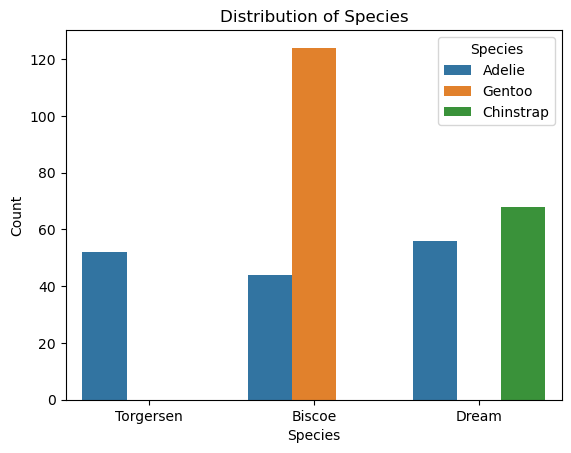

In [ ]:
sns.countplot(data=df, x="island", hue="species")
plt.title("Distribution of Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.legend(title="Species")
plt.show()

### Part 2 — Generate 50 random splits

In [ ]:
# Take a copy of the original dataframe
df_copy = df.copy()

results = []
splits = []

for i in range(50):

    # Step 1: Shuffle the dataset
    shuffled_df = df_copy.sample(frac=1, random_state=42 + i)

    n = len(shuffled_df)

    # Step 2: Calculate sizes
    train_size = round(n * 0.70)
    val_size = round(n * 0.20)
    test_size = n - train_size - val_size

    # Step 3: Split the dataset
    train = shuffled_df.iloc[:train_size].copy()
    val = shuffled_df.iloc[train_size:train_size + val_size].copy()
    test = shuffled_df.iloc[train_size + val_size:].copy()

    # Step 4: Calculate species proportions
    train_species = train["species"].value_counts(normalize=True)
    test_species = test["species"].value_counts(normalize=True)
    val_species = val["species"].value_counts(normalize=True)

    #  Step 4: Calculate island proportions\
    train_island = train["island"].value_counts(normalize=True)
    test_island = test["island"].value_counts(normalize=True)
    val_island = val["island"].value_counts(normalize=True)
    
    
    # Step 6: Verify the splits
    assert len(train) + len(val) + len(test) == n

    assert set(train.index).isdisjoint(set(val.index))
    assert set(train.index).isdisjoint(set(test.index))
    assert set(val.index).isdisjoint(set(test.index))

    # Step 7: Store proportions and sizes
    results.append({
        "candidate": i + 1,
        "train_size": len(train),
        "val_size": len(val),
        "test_size": len(test),
        "train_species": train_species.to_dict(),
        "val_species": val_species.to_dict(),
        "test_species": test_species.to_dict(),
        "train_island": train_island.to_dict(),
        "val_island": val_island.to_dict(),
        "test_island": test_island.to_dict()
    })

    # Step 8: Store the actual datasets
    splits.append({
        "candidate": i + 1,
        "train": train,
        "validation": val,
        "test": test
    })

# Step 9: Convert results to DataFrame
results_df = pd.DataFrame(results)

# Display results
print(results_df.head())

print("Total candidates:", len(results_df))

   candidate  train_size  val_size  test_size  \
0          1         241        69         34   
1          2         241        69         34   
2          3         241        69         34   
3          4         241        69         34   
4          5         241        69         34   

                                       train_species  \
0  {'Adelie': 0.44813278008298757, 'Gentoo': 0.35...   
1  {'Adelie': 0.46887966804979253, 'Gentoo': 0.36...   
2  {'Adelie': 0.4190871369294606, 'Gentoo': 0.365...   
3  {'Adelie': 0.42738589211618255, 'Gentoo': 0.36...   
4  {'Adelie': 0.44813278008298757, 'Gentoo': 0.34...   

                                         val_species  \
0  {'Adelie': 0.42028985507246375, 'Gentoo': 0.37...   
1  {'Adelie': 0.391304347826087, 'Gentoo': 0.3913...   
2  {'Adelie': 0.4927536231884058, 'Gentoo': 0.362...   
3  {'Adelie': 0.463768115942029, 'Gentoo': 0.3333...   
4  {'Adelie': 0.42028985507246375, 'Gentoo': 0.40...   

                               

Part 3 — Find the three closest distributions